# Industry Momentum: An Exploratory Tryout

> **Status: exploratory.** This notebook is a first pass at a classic anomaly, written to learn the mechanics end to end: signal construction, factor-model alphas, crash behavior, and after-tax implementation. It is not a finished research result. The rebound filter and tax-aware rules were designed with the full sample in view, there are no trading costs, and nothing here has been tested out of sample. See **Next steps** at the end.

**Contents**
1. 12-2 momentum on the 49 Fama-French industries, 1970-2025
2. Risk-adjusted performance (FF3 / FF5, Newey-West)
3. Crash analysis and a market-rebound filter
4. Capital-gains taxes: a lot-level tax engine and tax-aware execution
5. Robustness checks

Data: [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). The next cell downloads the three files into `data/` on first run.

## 1. The strategy

We construct a monthly long-short momentum strategy using
the 49 Fama-French value-weighted industry portfolios
over Jan 1970 - Dec 2025.

## Momentum Signal and Portfolio Formation

For each industry $i$, we define the 12-2 momentum signal as

$
M_{i,t}=\prod_{k=2}^{12}(1+r_{i,t-k})-1,
$

where $r_{i,t}$ denotes the monthly return of industry $i$.
The signal measures cumulative returns from month $t-12$
through month $t-2$, excluding the immediately preceding
month $t-1$.

The exclusion of the most recent month is motivated by
**short-term return reversals**. While momentum tends to persist
over intermediate horizons, very recent returns may exhibit
mean reversion due to liquidity
effects or investor overreaction. Skipping month $t-1$
reduces the influence of these short-term reversals on
the momentum signal.

At the beginning of each month, we rank all industries by
their momentum signals. We take equal-weighted long positions
in the 10 highest-ranked industries and equal-weighted short
positions in the 10 lowest-ranked industries, and
the portfolio is rebalanced monthly.

To ensure that the strategy is implementable, portfolio
weights for month $t$ are determined exclusively using
returns observed before month $t$. Specifically, the
momentum signal uses only returns through month $t-2$,
while the portfolio return is realized during month $t$.
For example, the January 2025 portfolio is formed using
returns from January through November 2024, excluding
December 2024. The resulting positions earn returns
during January 2025.

This separation between the formation and holding periods
prevents future realized returns from influencing portfolio
selection and avoids look-ahead bias.

## Portfolio Returns and Performance Evaluation

The monthly long-short strategy return is

$
R_{MOM,t}
=
\frac{1}{10}\sum_{i\in W_t}r_{i,t}
-
\frac{1}{10}\sum_{i\in L_t}r_{i,t}
$

where $W_t$ and $L_t$ denote the sets of winning and losing
industries selected for month $t$.

Starting with an initial investment of \$1, cumulative
portfolio wealth is computed as

$
V_t=\prod_{s=1}^{t}(1+R_{MOM,s})
$

and the geometric average monthly return is
$
\bar{R}_{geo}=V_T^{1/T}-1
$

where $T$ is the total number of monthly observations.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import io, re, zipfile, urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)
FRENCH_FTP = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
FILES = {
    "49_Industry_Portfolios.csv":          "49_Industry_Portfolios_CSV.zip",
    "F-F_Research_Data_Factors.csv":       "F-F_Research_Data_Factors_CSV.zip",
    "F-F_Research_Data_5_Factors_2x3.csv": "F-F_Research_Data_5_Factors_2x3_CSV.zip",
}

def fetch_french(name):
    """Download one Ken French CSV into data/ unless it is already there."""
    path = DATA / name
    if not path.exists():
        req = urllib.request.Request(FRENCH_FTP + FILES[name], headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, zipfile.ZipFile(io.BytesIO(resp.read())) as z:
            member = next(m for m in z.namelist() if m.lower().endswith(".csv"))
            path.write_bytes(z.read(member))
    return path

def read_french(name):
    """Return the first monthly block (rows indexed YYYYMM) of a Ken French CSV, in percent."""
    lines = fetch_french(name).read_text(encoding="latin-1").splitlines()
    is_month = lambda s: re.fullmatch(r"\s*\d{6}\s*", s.split(",")[0]) is not None
    start = next(i for i, l in enumerate(lines) if is_month(l))
    end = start
    while end < len(lines) and is_month(lines[end]):
        end += 1
    block = "\n".join([lines[start - 1]] + lines[start:end])   # header row + monthly rows
    return pd.read_csv(io.StringIO(block), index_col=0)


In [ ]:
START, END = "1970-01", "2025-12"

# Monthly value-weighted industry returns
ind = read_french("49_Industry_Portfolios.csv")
ind.columns = ind.columns.str.strip()
ind.index = pd.to_datetime(ind.index.astype(str), format="%Y%m").to_period("M")
ind = ind.replace([-99.99, -999], np.nan) / 100

print(ind.loc[START:END].shape)
display(ind.loc[START:END].head())

(672, 49)


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
1970-01,0.0101,-0.0277,-0.0279,-0.0136,-0.0699,-0.0802,-0.0563,-0.1140,-0.0690,-0.0480,...,-0.0847,-0.0782,-0.0797,-0.0589,-0.1192,-0.0752,-0.0896,-0.1136,-0.1070,-0.0511
1970-02,0.0993,0.0601,0.0388,0.0687,0.0028,0.0604,0.0822,0.0052,0.0027,0.0269,...,0.0681,0.1049,0.0382,0.0605,0.0537,0.1555,0.1049,0.0151,0.0911,-0.0526
1970-03,-0.1339,-0.0056,-0.0110,-0.0062,0.0142,-0.0282,-0.0258,-0.0270,-0.0096,-0.0057,...,-0.0232,-0.0318,-0.0562,-0.0092,-0.0757,-0.0122,-0.0022,-0.0101,-0.0057,0.0007
1970-04,-0.1769,-0.1055,-0.0867,-0.0940,-0.0281,-0.1988,-0.2150,-0.1505,-0.0792,-0.1414,...,-0.1078,-0.1200,-0.2066,-0.1001,-0.1841,-0.1093,-0.1529,-0.1865,-0.1248,-0.2869
1970-05,-0.0988,-0.0863,-0.0365,-0.0609,0.0355,-0.0791,-0.1323,-0.1759,-0.0822,-0.1030,...,-0.1039,-0.0689,-0.1205,-0.0939,-0.1209,-0.0649,-0.0874,-0.1517,-0.0944,-0.0546


In [ ]:
# 12-2 momentum: cumulative returns from t-12 to t-2
momentum = (
    (1 + ind.shift(2)).rolling(11).apply(np.prod, raw=True) - 1
).loc[START:END]

# Rank industries and select top/bottom 10
long = momentum.rank(axis=1, ascending=False, method="first") <= 10
short = momentum.rank(axis=1, ascending=True, method="first") <= 10

# Monthly holding-period returns
r = ind.loc[START:END]

assert (r.where(long).count(axis=1) == 10).all()
assert (r.where(short).count(axis=1) == 10).all()

# Equal-weighted portfolio returns
monthly = pd.DataFrame({
    "Long": r.where(long).mean(axis=1),
    "Short": r.where(short).mean(axis=1)
})

monthly["Momentum"] = monthly["Long"] - monthly["Short"]

display(monthly.head())

,Long,Short,Momentum
1970-01,-0.06786,-0.10950,0.04164
1970-02,0.04978,0.03522,0.01456
1970-03,-0.03852,-0.03130,-0.00722
1970-04,-0.11194,-0.18189,0.06995
1970-05,-0.04272,-0.11330,0.07058


Sample: 1970-01 to 2025-12
Number of months: 672
Geometric monthly return: 0.5211%
Annualized geometric return: 6.4361%
Final portfolio value: $32.8840


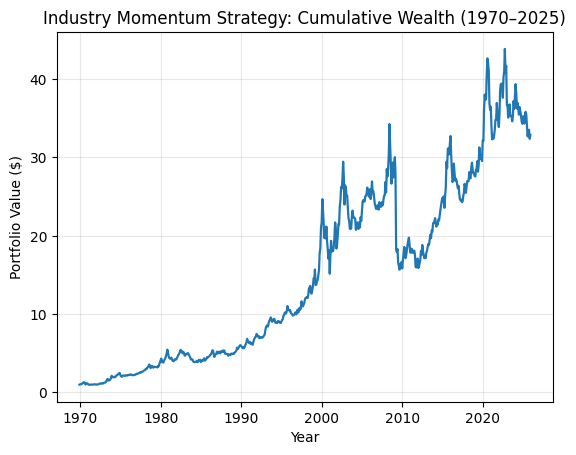

In [ ]:
# Cumulative wealth starting from $1
wealth = (1 + monthly["Momentum"]).cumprod()

# Geometric average monthly return
geo_return = wealth.iloc[-1] ** (1 / len(wealth)) - 1

# Gross long-short backtest returns, before trading costs, shorting costs, financing frictions, and taxes
print(f"Sample: {START} to {END}")
print(f"Number of months: {len(monthly)}")
print(f"Geometric monthly return: {geo_return:.4%}")
print(f"Annualized geometric return: {(1 + geo_return)**12 - 1:.4%}")
print(f"Final portfolio value: ${wealth.iloc[-1]:.4f}")

# Include initial wealth of $1
wealth = pd.concat([
    pd.Series({pd.Period("1969-12", freq="M"): 1.0}),
    wealth
])

plt.figure()
plt.plot(wealth.index.to_timestamp(), wealth.values, linewidth=1.6)
plt.title("Industry Momentum Strategy: Cumulative Wealth (1970–2025)")
plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Alpha of the strategy against the Fama-French 3- and 5-factor models

ff3 = read_french("F-F_Research_Data_Factors.csv")
ff3.columns = ff3.columns.str.strip()
ff3.index = pd.to_datetime(ff3.index.astype(str), format="%Y%m").to_period("M")
ff3 = ff3.replace([-99.99, -999], np.nan) / 100
ff3 = ff3.loc[START:END]

ff5 = read_french("F-F_Research_Data_5_Factors_2x3.csv")
ff5.columns = ff5.columns.str.strip()
ff5.index = pd.to_datetime(ff5.index.astype(str), format="%Y%m").to_period("M")
ff5 = ff5.replace([-99.99, -999], np.nan) / 100
ff5 = ff5.loc[START:END]

print(ff3.shape, ff5.shape)
display(ff3.head())
display(ff5.head())

(672, 4) (672, 6)


,Mkt-RF,SMB,HML,RF
1970-01,-0.0810,0.0291,0.0317,0.0060
1970-02,0.0514,-0.0239,0.0369,0.0062
1970-03,-0.0106,-0.0231,0.0408,0.0057
1970-04,-0.1099,-0.0614,0.0614,0.0050
1970-05,-0.0690,-0.0461,0.0332,0.0053


,Mkt-RF,SMB,HML,RMW,CMA,RF
1970-01,-0.0811,0.0308,0.0317,-0.0175,0.0396,0.0060
1970-02,0.0514,-0.0257,0.0369,-0.0241,0.0287,0.0062
1970-03,-0.0106,-0.0242,0.0408,-0.0106,0.0442,0.0057
1970-04,-0.1099,-0.0634,0.0614,-0.0063,0.0590,0.0050
1970-05,-0.0691,-0.0446,0.0332,-0.0129,0.0379,0.0053


In [ ]:
import statsmodels.api as sm

y = monthly["Momentum"]

factors3 = ["Mkt-RF", "SMB", "HML"]
factors5 = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]

def run_regression(y, factors, columns):
    data = pd.concat([y, factors[columns]], axis=1).dropna()
    assert len(data) == 672
    X = sm.add_constant(data[columns])

    return sm.OLS(data[y.name], X).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6}   # Newey-West SE
    )

model3 = run_regression(y, ff3, factors3)
model5 = run_regression(y, ff5, factors5)

results = pd.DataFrame({
    "FF3": {
        "Monthly Alpha (%)": model3.params["const"] * 100,
        "Annualized Alpha (%)": model3.params["const"] * 1200,
        "Alpha t-stat": model3.tvalues["const"],
        "Alpha p-value": model3.pvalues["const"],
        "R-squared": model3.rsquared,
        "Observations": model3.nobs
    },
    "FF5": {
        "Monthly Alpha (%)": model5.params["const"] * 100,
        "Annualized Alpha (%)": model5.params["const"] * 1200,
        "Alpha t-stat": model5.tvalues["const"],
        "Alpha p-value": model5.pvalues["const"],
        "R-squared": model5.rsquared,
        "Observations": model5.nobs
    }
})

display(results.round(4))

,FF3,FF5
Monthly Alpha (%),0.8253,0.7369
Annualized Alpha (%),9.9039,8.8427
Alpha t-stat,4.7961,3.7985
Alpha p-value,0.0000,0.0001
R-squared,0.0634,0.0798
Observations,672.0000,672.0000


We evaluated the risk-adjusted performance of our momentum
strategy using the FF3 and FF5 models. We estimate both models using OLS and report Newey-West standard errors with six monthly lags.

Both models yield positive and statistically significant
alphas at the 1\% level. The monthly alpha decreases
from 0.8253\% under FF3 to 0.7369\% under FF5,
indicating that the additional profitability and
investment factors explain part of the strategy's
returns. Nevertheless, the remaining positive alpha
suggests that the momentum premium is not fully
captured by these conventional risk factors.

The relatively low R-squared values also suggest
that the strategy's monthly return variation is
largely unexplained by the identified factors.
It is worth to note that these results are based on gross strategy returns
before considering market frictions.




In [ ]:
# Periods in which the strategy did very well and very poorly
base = monthly["Momentum"]

# Best and worst monthly performance
print("Best 5 months (%):")
display((monthly.nlargest(5, "Momentum") * 100).round(2))

print("Worst 5 months (%):")
display((monthly.nsmallest(5, "Momentum") * 100).round(2))

# Annual compounded returns
annual = (1 + base).groupby(base.index.year).prod() - 1

print("Best 5 years (%):")
display((annual.nlargest(5) * 100).round(2))

print("Worst 5 years (%):")
display((annual.nsmallest(5) * 100).round(2))

# Maximum drawdown
wealth_base = (1 + base).cumprod()
drawdown = wealth_base / wealth_base.cummax() - 1
print(f"Maximum drawdown: {drawdown.min():.2%}")

Best 5 months (%):


,Long,Short,Momentum
2001-02,5.58,-11.08,16.66
1999-12,15.50,1.29,14.21
1999-10,6.16,-7.62,13.78
2000-02,8.14,-5.60,13.73
1973-12,9.43,-4.23,13.66


Worst 5 months (%):


,Long,Short,Momentum
2009-04,1.16,36.14,-34.98
1970-09,4.98,21.79,-16.81
2001-01,-5.24,11.15,-16.39
2002-11,0.41,13.54,-13.14
2001-11,-0.86,12.09,-12.94


Best 5 years (%):


,Momentum
1973,75.02
1999,55.23
2002,39.58
1980,30.64
2015,29.52


Worst 5 years (%):


,Momentum
2009,-39.34
2016,-17.85
1981,-16.33
2003,-14.92
1983,-14.89


Maximum drawdown: -54.24%


## Strategy Adjustment

After the examination, we observe that in the worst 5 months
the short portfolio consistently generated positive returns,
with particularly sharp rebounds in April 2009 (36.14\%)
and September 1970 (21.79\%). This suggests that momentum
crashes are largely driven by abrupt reversals among
previously underperforming industries.

To mitigate this risk, we introduce a conditional long-only
strategy. When the market has experienced

- a negative cumulative return over the preceding 12 months

- a positive return in the most recent month

we close our short positions while maintaining the equal-weighted long portfolio; otherwise, we retain the original long-short strategy.

The adjusted excess return is therefore

$
R_{adj,t} =
\begin{cases}
R_{L,t}-R_{f,t}, & \text{if rebound conditions hold}\\
R_{L,t}-R_{S,t}, & \text{otherwise}
\end{cases}
$

This adjustment aims to reduce losses from sharp recoveries
among previous losers while preserving exposure to momentum
winners. All signals are based on information available
before the holding month, avoiding look-ahead bias.

In [ ]:
# Reload full FF3 history, including pre-1970 data
factors = read_french("F-F_Research_Data_Factors.csv")
factors.columns = factors.columns.str.strip()
factors.index = pd.to_datetime(factors.index.astype(str), format="%Y%m").to_period("M")

mkt = (factors["Mkt-RF"] + factors["RF"]) / 100
rf = factors["RF"].reindex(monthly.index) / 100

# Rebound signal: negative past 12 months, positive last month
past_12m = (1 + mkt).rolling(12).apply(np.prod, raw=True).shift(1) - 1
risk_off = ((past_12m < 0) & (mkt.shift(1) > 0)).reindex(monthly.index).fillna(False)

# Long-only during rebound periods; long-short otherwise
adjusted = monthly["Momentum"].where(~risk_off, monthly["Long"] - rf)

print("Long-only months:", risk_off.sum())
print("April 2009 signal:", risk_off.loc["2009-04"])

Long-only months: 63
April 2009 signal: True


,Geometric Monthly Return (%),Maximum Drawdown (%),Final Portfolio Value ($)
Original,0.5211,-54.2424,32.8840
Adjusted,0.6853,-43.5572,98.4441


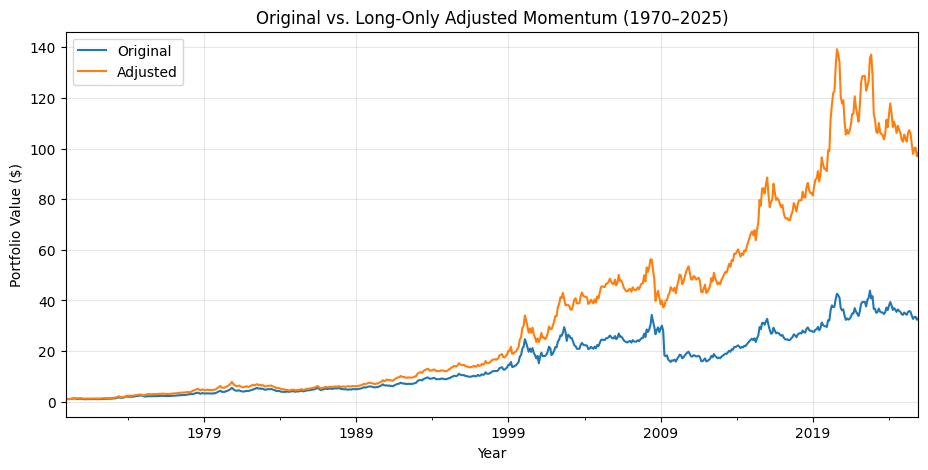

In [ ]:
# Compare backtest performance
returns = pd.DataFrame({
    "Original": monthly["Momentum"],
    "Adjusted": adjusted
})

wealth = (1 + returns).cumprod()

# Include initial wealth of $1 for drawdown calculations
wealth = pd.concat([
    pd.DataFrame(1.0, index=[returns.index[0] - 1],
                 columns=returns.columns),
    wealth
])

results = pd.DataFrame({
    "Geometric Monthly Return (%)":
        ((wealth.iloc[-1] ** (1 / len(returns))) - 1) * 100,
    "Maximum Drawdown (%)":
        ((wealth / wealth.cummax()) - 1).min() * 100,
    "Final Portfolio Value ($)": wealth.iloc[-1]
})

display(results.round(4))

wealth.to_timestamp().plot(figsize=(11, 5), linewidth=1.5)

plt.title("Original vs. Long-Only Adjusted Momentum (1970–2025)")
plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The adjusted strategy improves the geometric monthly return
from 0.5211\% to 0.6853\%, increasing the terminal value
of an initial \$1 investment from \$32.88 to \$98.44.
Meanwhile, the maximum drawdown decreases from 54.24\%
to 43.56\%, suggesting improved downside protection.

However, this adjustment changes the strategy's risk exposure. By replacing the dollar-neutral long-short portfolio with a long-only portfolio during market rebounds, the strategy eliminates short-leg reversal risk but potentially increases its exposure to systematic market risk. The improvement is consistent with avoiding substantial short-leg reversal losses, although the resulting increase in market exposure may also contribute to performance. It does not indicate a better signal, since the momentum ranking is unchanged, and we examine the role of market exposure below by comparing alternative adjustments. Moreover, the adjustment was motivated by historical losses, so the in-sample improvement may not survive out-of-sample.

## Taxes on Capital Gains

The results above are gross returns. We now ask how much of the rebound-adjusted strategy survives capital-gains taxes and how the implementation should change. We assume a taxable investor with a short-term rate $\tau_S=35\%$ (positions held less than 12 months) and a long-term rate $\tau_L=20\%$ (held 12 months or more).

### Tax accounting

Every purchase is tracked as a separate **tax lot** (industry, side, cost basis, open date). Selling (or covering) a lot realizes

$
G_{long}=q\,(P_{sell}-P_{basis}),\qquad G_{short}=q\,(P_{basis}-P_{cover}),
$

and the gain or loss is classified as short- or long-term by the lot's holding period. Taxes are settled each December. Let $S_y$ and $L_y$ be the year's net short- and long-term results after (i) netting within each category, (ii) netting across categories (a loss in one category offsets a gain in the other), and (iii) adding unused losses carried forward, which we assume never expire. Then

$
\text{Tax}_y=\tau_S\max(S_y,0)+\tau_L\max(L_y,0),
$

and any remaining net loss is carried forward. Taxes are paid out of portfolio wealth, and unrealized gains are not taxed until sold (we also report the value if everything were liquidated at the end).

Other assumptions: strategy returns are excess returns as above (each position earns $r_{i,t}-r_{f,t}$); capital gains are computed from total-return prices, so dividends are not taxed separately; no trading costs, state taxes, or wash-sale rule; and short positions use the same holding-period rule as longs for simplicity (under actual US law short-sale gains are generally short-term, which we test below).

### Tax-aware adjustments

The signal and the rebound rule are unchanged, so no future information is used. Starting from the naive implementation, we add one feature at a time:

- **A. Naive:** rebalance to equal weights every month, sell oldest lots first (FIFO). This is exactly the portfolio above, now taxed.
- **B. Specific-lot selection:** when part of a position is sold, sell the lots with the lowest tax cost first (losses, then long-term, then short-term). This changes taxes only, not pre-tax returns.
- **C. Trade only on entry/exit:** do not trim or top up continuing positions each month, since trimming a winner realizes a short-term gain. New names are sized so each leg returns to about 100\% of capital (bounded between 0.5x and 1.5x the equal weight) so leverage and market exposure stay comparable.
- **D. Symmetric exit buffer:** keep a position until its momentum rank falls beyond 20 (instead of 10), which reduces turnover.
- **E. Asymmetric buffer:** cut losers, let winners run. A position with an unrealized *loss* is sold as soon as it leaves the top 10, which realizes the loss early when it is most valuable against future 35\% short-term gains. A position with an unrealized *gain* is kept until its rank falls beyond 20, which defers the tax and lets more gains reach the 20\% long-term rate. The cutoff of 20 (2x the portfolio size) is a round number, not tuned. We show other values below.

In [ ]:
# Tax engine: lot-level simulation of the long-short strategy with capital-gains taxes
def tax_backtest(R, rf, rank_desc, rank_asc, risk_off=None, N=10, tau_s=0.35, tau_l=0.20,
                 rebalance="full", entry_size="equal", exit_rank=None, exit_rank_gain=None,
                 lot_rule="fifo", shorts_always_st=False, liquidate=True):
    """Monthly long/short industry strategy with lot-level capital-gains taxes.
    rebalance   : 'full' = restore equal weights every month; 'none' = trade only on entry/exit
    entry_size  : 'equal' = V/N per new name; 'fill' = new names absorb drift so each leg is ~100% of capital
    exit_rank   : keep an incumbent until its rank is worse than this (default N, i.e. hold exactly the top N)
    exit_rank_gain: if set, incumbents with an unrealised GAIN are kept until rank > this; losers are cut at rank > N
    lot_rule    : 'fifo' or 'tax' (sell lots with the lowest tax cost first, i.e. losses first)"""
    T, n = R.shape
    Rv, rfv = R.values, np.asarray(rf, float)
    rank = {+1: rank_desc.fillna(np.inf).values, -1: rank_asc.fillna(np.inf).values}
    off = np.zeros(T, bool) if risk_off is None else np.asarray(risk_off, bool)
    months = R.index.month.values
    P = np.ones(n)                                    # total-return price index of each industry
    lots = {+1: {}, -1: {}}                           # side -> industry -> [[units, basis price, open idx], ...]
    V, cf, ytd = 1.0, dict(st=0.0, lt=0.0), dict(st=0.0, lt=0.0)   # wealth, loss carryforwards, realised gains this year
    Vpath, tax_paid, turn, gross = np.zeros(T), np.zeros(T), np.zeros(T), np.zeros((T, 2))
    gpos, hold = dict(st=0.0, lt=0.0), [0.0, 0.0]

    value = lambda side, j: sum(l[0] for l in lots[side].get(j, [])) * P[j]
    unreal = lambda side, j: sum(l[0] * side * (P[j] - l[1]) for l in lots[side][j])
    term = lambda side, age: "st" if (age < 12 or (side == -1 and shorts_always_st)) else "lt"

    def sell(side, j, amount, k):
        ls = lots[side][j]; amount = min(amount, value(side, j)); left = amount / P[j]
        if lot_rule == "fifo": order = sorted(ls, key=lambda l: l[2])
        else: order = sorted(ls, key=lambda l: side * (P[j] - l[1]) * (tau_s if term(side, k - l[2]) == "st" else tau_l))
        for l in order:
            if left <= 1e-15: break
            u = min(l[0], left); g = u * side * (P[j] - l[1]); tm = term(side, k - l[2])
            ytd[tm] += g; gpos[tm] += max(g, 0.0)
            hold[0] += (k - l[2]) * u * P[j]; hold[1] += u * P[j]
            l[0] -= u; left -= u
        lots[side][j] = [l for l in ls if l[0] > 1e-15]
        if not lots[side][j]: del lots[side][j]
        return amount

    def buy(side, j, amount, k):
        lots[side].setdefault(j, []).append([amount / P[j], P[j], k]); return amount

    def settle(cf, st, lt):          # net ST/LT within category, then across; losses carry forward indefinitely
        S, L = cf["st"] + st, cf["lt"] + lt
        if S < 0 < L: u = min(-S, L); S, L = S + u, L - u
        elif L < 0 < S: u = min(-L, S); L, S = L + u, S - u
        return tau_s * max(S, 0) + tau_l * max(L, 0), dict(st=min(S, 0), lt=min(L, 0))

    for k in range(T):
        w = V / N
        # 1) target names (ranks already use returns through t-2 only)
        tgt = {}
        for side in (+1, -1):
            if side == -1 and off[k]: tgt[side] = set(); continue
            rk = rank[side][k]
            if exit_rank_gain: keep = {j for j in lots[side] if rk[j] <= (exit_rank_gain if unreal(side, j) > 0 else N)}
            else:              keep = {j for j in lots[side] if rk[j] <= (exit_rank or N)}
            fill = [j for j in np.argsort(rk) if j not in keep and np.isfinite(rk[j])][:N - len(keep)]
            tgt[side] = keep | set(fill)
        # 2) trade
        tr = 0.0
        for side in (+1, -1):
            for j in [j for j in lots[side] if j not in tgt[side]]: tr += sell(side, j, value(side, j), k)
            held = [j for j in tgt[side] if value(side, j) > 0]; new = [j for j in tgt[side] if j not in held]
            if rebalance == "full":
                for j in held:
                    v = value(side, j)
                    if v > w: tr += sell(side, j, v - w, k)
                    elif v < w: tr += buy(side, j, w - v, k)
            size = w
            if entry_size == "fill" and new:
                size = float(np.clip((V - sum(value(side, j) for j in held)) / len(new), 0.5 * w, 1.5 * w))
            for j in new: tr += buy(side, j, size, k)
        turn[k] = tr / V
        # 3) earn excess returns on positions, then roll prices forward
        pnl = 0.0
        for side in (+1, -1):
            gross[k, 0 if side == 1 else 1] = sum(value(side, j) for j in lots[side]) / V
            pnl += sum(side * value(side, j) * (Rv[k, j] - rfv[k]) for j in lots[side])
        V += pnl; P = P * (1 + Rv[k])
        # 4) pay the year's capital-gains tax in December
        if months[k] == 12:
            tax, cf = settle(cf, ytd["st"], ytd["lt"]); V -= tax; tax_paid[k] = tax; ytd = dict(st=0.0, lt=0.0)
        Vpath[k] = V
    V_liq = V                         # hypothetical liquidation at the end of the sample
    if liquidate:
        for side in (+1, -1):
            for j in list(lots[side]): sell(side, j, value(side, j), T)
        V_liq = V - settle(cf, ytd["st"], ytd["lt"])[0]
    idx = R.index
    return dict(V=pd.Series(Vpath, idx), V_liq=V_liq, tax_paid=pd.Series(tax_paid, idx), turnover=pd.Series(turn, idx),
                gross=pd.DataFrame(gross, idx, ["long", "short"]), avg_hold=hold[0] / hold[1],
                lt_share=gpos["lt"] / (gpos["lt"] + gpos["st"]))

In [ ]:
# Setup: same signals, returns and rebound rule as above
R = ind.loc[START:END]
rank_desc = momentum.rank(axis=1, ascending=False, method="first")   # 1 = strongest winner
rank_asc  = momentum.rank(axis=1, ascending=True,  method="first")   # 1 = strongest loser
T = len(R)
geo = lambda v: (v ** (1 / T) - 1) * 100                              # geometric monthly return, in %

def run(rebound, tau=(0.35, 0.20), **kw):
    return tax_backtest(R, rf.values, rank_desc, rank_asc, risk_off=rebound,
                        tau_s=tau[0], tau_l=tau[1], **kw)

MAIN = "Rebound-adjusted strategy"
bases = {MAIN: risk_off.values,
         "Original strategy": None}

# Check: with zero taxes the engine must reproduce the original and rebound-adjusted wealth paths exactly
for name, rebound, ref in [("Original", None, monthly["Momentum"]), ("Adjusted", risk_off.values, adjusted)]:
    assert np.allclose(run(rebound, tau=(0, 0))["V"], (1 + ref).cumprod(), rtol=1e-9)
print("Zero-tax check passed: the engine reproduces the original and rebound-adjusted wealth paths exactly.\n")

# Strategy variants (each adds one tax-aware feature)
variants = {
    "A. Naive (monthly rebalance, FIFO)": dict(rebalance="full", lot_rule="fifo"),
    "B. + specific-lot selection":        dict(rebalance="full", lot_rule="tax"),
    "C. + trade only on entry/exit":      dict(rebalance="none", entry_size="fill", lot_rule="tax"),
    "D. + symmetric buffer (rank 20)":    dict(rebalance="none", entry_size="fill", lot_rule="tax", exit_rank=20),
    "E. + asymmetric buffer (20 / 10)":   dict(rebalance="none", entry_size="fill", lot_rule="tax", exit_rank_gain=20),
}
NAIVE, AWARE = list(variants)[0], list(variants)[-1]

store = {}
for bname, rebound in bases.items():
    rows = {}
    for vname, kw in variants.items():
        pre = run(rebound, tau=(0, 0), liquidate=False, **kw)     # same strategy without taxes
        at  = run(rebound, **kw)                                  # 35% short-term / 20% long-term
        store[(bname, vname)] = (pre, at)
        p, a = geo(pre["V"].iloc[-1]), geo(at["V"].iloc[-1])
        rows[vname] = {
            "Pre-tax (%/mo)": p, "After-tax (%/mo)": a, "Tax drag (% of pre-tax)": (p - a) / p * 100,
            "Pre-tax value ($)": pre["V"].iloc[-1], "After-tax value ($)": at["V"].iloc[-1],
            "If liquidated ($)": at["V_liq"],
            "Turnover (x/yr)": at["turnover"].mean() * 12, "Avg holding (mo)": at["avg_hold"],
            "LT share of gains (%)": at["lt_share"] * 100,
            "Avg long / short exposure": f'{at["gross"]["long"].mean():.2f} / {at["gross"]["short"].mean():.2f}'}
    print(bname)
    display(pd.DataFrame(rows).T.round(3))

Zero-tax check passed: the engine reproduces the original and rebound-adjusted wealth paths exactly.

Rebound-adjusted strategy


,Pre-tax (%/mo),After-tax (%/mo),Tax drag (% of pre-tax),Pre-tax value ($),After-tax value ($),If liquidated ($),Turnover (x/yr),Avg holding (mo),LT share of gains (%),Avg long / short exposure
"A. Naive (monthly rebalance, FIFO)",0.685297,0.515271,24.810529,98.444078,31.618188,31.618188,12.184665,3.76828,23.337376,1.00 / 0.91
B. + specific-lot selection,0.685297,0.523392,23.625536,98.444078,33.382167,33.382167,12.183966,3.768837,26.648886,1.00 / 0.91
C. + trade only on entry/exit,0.63369,0.476028,24.87997,69.753146,24.320517,24.320517,10.944423,4.164887,36.001898,1.00 / 0.90
D. + symmetric buffer (rank 20),0.59917,0.472152,21.198934,55.390394,23.698117,23.461009,4.989898,9.177572,59.449384,1.01 / 0.90
E. + asymmetric buffer (20 / 10),0.693867,0.551515,20.515713,104.238595,40.285781,38.436254,7.0121,6.552814,59.272206,1.02 / 0.88


Original strategy


,Pre-tax (%/mo),After-tax (%/mo),Tax drag (% of pre-tax),Pre-tax value ($),After-tax value ($),If liquidated ($),Turnover (x/yr),Avg holding (mo),LT share of gains (%),Avg long / short exposure
"A. Naive (monthly rebalance, FIFO)",0.521143,0.410191,21.290123,32.883995,15.655852,15.655852,11.803231,4.075208,29.147699,1.00 / 1.00
B. + specific-lot selection,0.521143,0.431066,17.284434,32.883995,18.003022,18.003022,11.801659,4.088812,37.028745,1.00 / 1.00
C. + trade only on entry/exit,0.48923,0.402127,17.804173,26.565483,14.833301,14.833301,10.528247,4.565626,46.677812,1.01 / 1.00
D. + symmetric buffer (rank 20),0.522764,0.439776,15.874787,33.242311,19.083373,17.759525,4.147576,11.309097,72.689799,1.01 / 0.97
E. + asymmetric buffer (20 / 10),0.64758,0.558829,13.705071,76.531972,42.303748,38.803768,6.080774,7.863424,74.316571,1.03 / 0.96


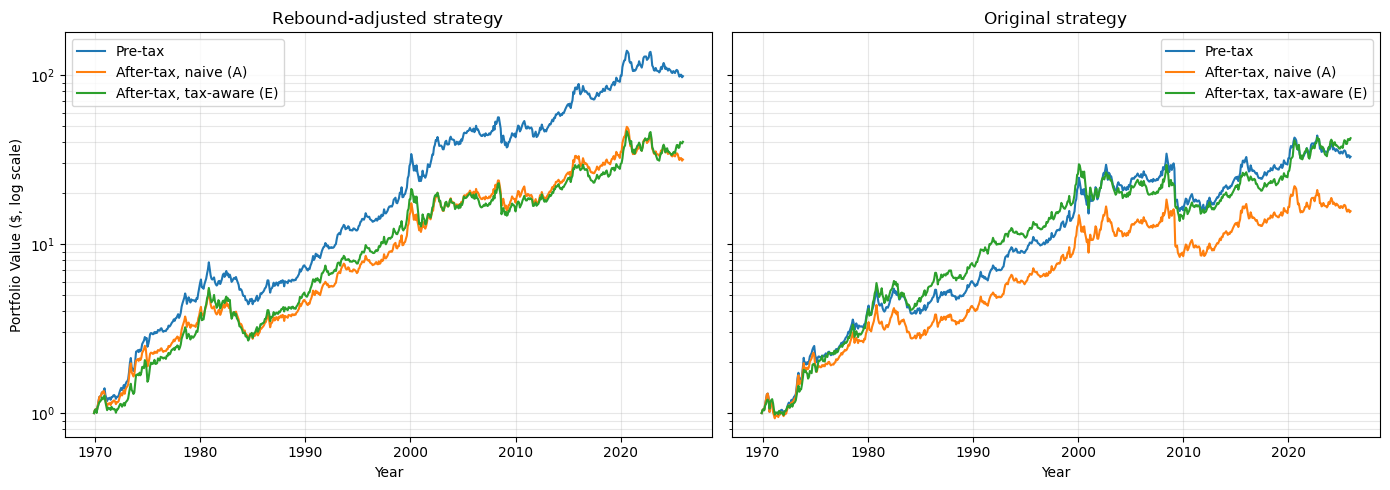

In [ ]:
# Portfolio value: pre-tax vs. after-tax (naive and tax-aware)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, bname in zip(axes, bases):
    pre, naive = store[(bname, NAIVE)]
    _, aware = store[(bname, AWARE)]
    for lab, v in {"Pre-tax": pre["V"], "After-tax, naive (A)": naive["V"],
                   "After-tax, tax-aware (E)": aware["V"]}.items():
        v = pd.concat([pd.Series({pd.Period("1969-12", freq="M"): 1.0}), v])   # start from $1
        ax.plot(v.index.to_timestamp(), v.values, label=lab, linewidth=1.5)
    ax.set_yscale("log")
    ax.set_title(bname)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
axes[0].set_ylabel("Portfolio Value ($, log scale)")
plt.tight_layout()
plt.show()

### Results

Taxes are costly in general. For the rebound-adjusted strategy, the naive implementation earns 0.685\% per month before tax but only 0.515\% after tax, taxes consume about 25\% of the compound return and \$1 grows to \$31.62 instead of \$98.44. The diagnostics explain why: positions are held 3.8 months on average, the book turns over about 12 times a year, and only 23\% of realized gains are long-term. A momentum signal is designed to rotate positions, so most gains are necessarily taxed at the 35\% short-term rate.

Adding features one at a time shows what helps and what does not:

- **B (lot selection)** is a pure tax effect: pre-tax returns are identical and the after-tax return rises slightly, from 0.515\% to 0.523\%.
- **C (no monthly rebalancing)** lowers taxes paid but also lowers the pre-tax return (0.634\%) because positions drift away from equal weights, so the after-tax return falls to 0.476\%. By itself it is not an improvement.
- **D (symmetric buffer)** cuts turnover from 12 to 5 times a year and lifts the long-term share to 59\%, but it slows down the signal: pre-tax return drops to 0.599\% and after-tax return to 0.472\%.
- **E (asymmetric buffer)** keeps the pre-tax return close to the naive one while reducing the tax drag. The after-tax return is 0.552% per month, and \$1 grows to \$40.29 (27\% more than naive), or \$38.44 if all positions are liquidated at the end. The tax-aware strategy improves after-tax returns through a combination of reduced tax drag and modest changes in pretax performance. Because portfolio composition and market exposure also change, the improvement cannot be attributed exclusively to tax efficiency.

The original strategy shows the same pattern: the tax drag falls from 21\% to 14\%. There, E also raises the pre-tax return (0.521\% to 0.648\%), so part of the improvement is not a tax effect, and the change in tax drag is the cleaner comparison.

The tax-aware implementation also changes how we should view the rebound adjustment. With naive execution the rebound rule still adds value after tax (0.515\% vs. 0.410\% for the original), though less than before tax (0.685\% vs. 0.521\%). With the tax-aware implementation, the adjusted strategy no longer beats the original after tax (0.552\% vs. 0.559\%). A likely reason is that the rule forces the whole short book to be covered at times dictated by the market, not by tax lots, which leaves less room to defer gains (long-term share 59\% vs. 74\% for the original), and that with loss carryforwards the tax system shares in the crash losses the rule avoids. We have not tested these explanations separately.

In [ ]:
# Robustness (a): width of the asymmetric buffer. After-tax geometric return (%/month)
short = {MAIN: "Adj", "Original strategy": "Orig"}
grid = {}
ks = [12, 14, 15, 16, 18, 20, 22, 25, 30]
for b, rb in bases.items():
    for tag, arg in [("asym", "exit_rank_gain"), ("sym", "exit_rank")]:
        grid[f"{short[b]} {tag}"] = {k: geo(run(rb, rebalance="none", entry_size="fill", lot_rule="tax",
                                                liquidate=False, **{arg: k})["V"].iloc[-1]) for k in ks}
grid = pd.DataFrame(grid)
grid.index.name = "rank cutoff k"
grid.loc["Naive (A)"] = [geo(store[(b, NAIVE)][1]["V"].iloc[-1]) for b in bases for _ in range(2)]
print("(a) After-tax return (%/mo) by buffer width. Adj = rebound-adjusted strategy, Orig = original strategy;")
print("    asym = winners kept to rank k, losers cut at 10;  sym = every position kept to rank k")
display(grid.round(4))

# Robustness (b): tax rates
# and (c) short-leg gains always short-term (as under actual US law)
rows = {}
for label, kw in {"35% / 20% (baseline)": dict(tau=(0.35, 0.20)),
                  "24% / 15% (middle bracket)": dict(tau=(0.24, 0.15)),
                  "40.8% / 23.8% (top bracket + 3.8% NIIT)": dict(tau=(0.408, 0.238)),
                  "20% / 20% (no short/long-term gap)": dict(tau=(0.20, 0.20)),
                  "35% / 20%, short-leg gains always short-term": dict(tau=(0.35, 0.20), shorts_always_st=True)}.items():
    row = {}
    for tag, vname in [("Naive (A)", NAIVE), ("Tax-aware (E)", AWARE)]:
        pre = store[(MAIN, vname)][0]
        at = run(bases[MAIN], liquidate=False, **kw, **variants[vname])
        p, a = geo(pre["V"].iloc[-1]), geo(at["V"].iloc[-1])
        row[f"{tag} after-tax (%/mo)"] = a
        row[f"{tag} drag (%)"] = (p - a) / p * 100
    rows[label] = row
print("(b)-(c) Tax rates (rebound-adjusted strategy)")
display(pd.DataFrame(rows).T.round(3))

(a) After-tax return (%/mo) by buffer width. Adj = rebound-adjusted strategy, Orig = original strategy;
    asym = winners kept to rank k, losers cut at 10;  sym = every position kept to rank k


,Adj asym,Adj sym,Orig asym,Orig sym
rank cutoff k,,,,
12,0.4697,0.4932,0.3866,0.4250
14,0.5490,0.5646,0.5086,0.5287
15,0.5839,0.5716,0.5734,0.5302
16,0.5913,0.5120,0.5714,0.4890
18,0.5566,0.4532,0.5651,0.4147
20,0.5515,0.4722,0.5588,0.4398
22,0.5539,0.4881,0.5553,0.5277
25,0.5405,0.4605,0.5463,0.4104
30,0.5537,0.3221,0.5877,0.3039


(b)-(c) Tax rates (rebound-adjusted strategy)


,Naive (A) after-tax (%/mo),Naive (A) drag (%),Tax-aware (E) after-tax (%/mo),Tax-aware (E) drag (%)
35% / 20% (baseline),0.515,24.811,0.552,20.516
24% / 15% (middle bracket),0.566,17.378,0.593,14.540
40.8% / 23.8% (top bracket + 3.8% NIIT),0.484,29.440,0.524,24.470
20% / 20% (no short/long-term gap),0.561,18.157,0.580,16.355
"35% / 20%, short-leg gains always short-term",0.507,26.005,0.544,21.541


In [ ]:
# Robustness (d): sub-periods, and (e) after-tax alpha

# monthly returns implied by a wealth path that starts at $1
def monthly_ret(v):
    r_ = v.pct_change()
    r_.iloc[0] = v.iloc[0] - 1
    return r_

paths = {}
for b in bases:
    paths[(b, "Pre-tax, naive (A)")]      = store[(b, NAIVE)][0]["V"]
    paths[(b, "After-tax, naive (A)")]    = store[(b, NAIVE)][1]["V"]
    paths[(b, "Pre-tax, tax-aware (E)")]  = store[(b, AWARE)][0]["V"]
    paths[(b, "After-tax, tax-aware (E)")] = store[(b, AWARE)][1]["V"]

def period_geo(r_, a, b_):
    x = r_.loc[a:b_]
    return ((1 + x).prod() ** (1 / len(x)) - 1) * 100

sub = {k: {"1970-1997": period_geo(monthly_ret(v), "1970-01", "1997-12"),
           "1998-2025": period_geo(monthly_ret(v), "1998-01", "2025-12")} for k, v in paths.items()}
print("(d) Geometric monthly return (%) by sub-period")
display(pd.DataFrame(sub).T.round(3))

alpha = {}
for k, v in paths.items():
    y_at = monthly_ret(v)
    y_at.name = "AfterTax"
    m3 = run_regression(y_at, ff3, factors3)
    m5 = run_regression(y_at, ff5, factors5)
    alpha[k] = {"FF3 alpha (%/mo)": m3.params["const"] * 100, "FF3 t-stat": m3.tvalues["const"],
                "FF5 alpha (%/mo)": m5.params["const"] * 100, "FF5 t-stat": m5.tvalues["const"]}
print("(e) Alpha of the taxed and untaxed strategies (Newey-West, 6 lags)")
display(pd.DataFrame(alpha).T.round(3))

(d) Geometric monthly return (%) by sub-period


1970-1997  1998-2025
Rebound-adjusted strategy Pre-tax, naive (A)            0.835      0.536
                                      After-tax, naive (A)          0.650      0.380
                                      Pre-tax, tax-aware (E)        0.894      0.494
                                      After-tax, tax-aware (E)      0.711      0.392
Original strategy         Pre-tax, naive (A)            0.738      0.305
                                      After-tax, naive (A)          0.602      0.219
                                      Pre-tax, tax-aware (E)        0.935      0.361
                                      After-tax, tax-aware (E)      0.817      0.302

(e) Alpha of the taxed and untaxed strategies (Newey-West, 6 lags)


FF3 alpha (%/mo)  FF3 t-stat  FF5 alpha (%/mo)  FF5 t-stat
Rebound-adjusted strategy Pre-tax, naive (A)                   0.842       4.788             0.790       4.280
                                      After-tax, naive (A)                 0.676       3.823             0.629       3.382
                                      Pre-tax, tax-aware (E)               0.813       4.527             0.756       4.046
                                      After-tax, tax-aware (E)             0.681       3.739             0.632       3.315
Original strategy         Pre-tax, naive (A)                   0.825       4.796             0.737       3.798
                                      After-tax, naive (A)                 0.715       4.139             0.628       3.238
                                      Pre-tax, tax-aware (E)               0.842       4.893             0.763       4.035
                                      After-tax, tax-aware (E)             0.759       4.393             0.685       3.623

### Robustness and conclusion

- **Buffer width.** The tax-aware result is not an artifact of the cutoff of 20. For the rebound-adjusted strategy the after-tax return is 0.54-0.59\% per month for every winner cutoff from 14 to 30, always above the naive 0.515\%. The same holds for the original strategy (0.51-0.59\% vs. 0.410\%). Only a cutoff of 12, which is barely wider than the top 10, fails to beat naive. In contrast, the *symmetric* buffer is erratic: for the rebound-adjusted strategy its after-tax return swings between 0.32\% and 0.57\% depending on the width and beats naive at only 2 of the 9 widths tested. This is why the asymmetry, not just lower turnover, is the key design choice.
- **Tax rates.** E beats the naive implementation under every rate pair, and the gap widens with the rates: 2.7 bp per month at 24\%/15\%, 3.6 bp at 35\%/20\%, and 4.1 bp at 40.8\%/23.8\%. With no gap between short- and long-term rates (20\%/20\%) the gain shrinks to about 2 bp, so most of it comes from the rate differential and the rest from deferral and earlier loss realization.
- **Short-leg gains always short-term.** Under this stricter rule E still beats naive (0.544\% vs. 0.507\%).
- **Sub-periods.** The after-tax improvement appears in both halves for the rebound-adjusted strategy, but it is concentrated in 1970-1997 (0.711\% vs. 0.650\%). In 1998-2025 it is small (0.392\% vs. 0.380\%), consistent with weaker momentum in the later sample.
- **After-tax alpha.** Both taxed strategies keep statistically significant FF3 and FF5 alphas (roughly 0.63-0.68\% per month for the rebound-adjusted strategy, down from 0.76-0.84\% before tax). For the rebound-adjusted strategy, however, E does not raise alpha relative to naive; part of its higher raw return comes from a slightly net-long book (average long exposure 1.02 vs. short 0.88), which carries market beta.

**Conclusion.**

With capital-gains taxes, we would
- pick tax lots with the lowest tax cost when selling,
- trade only when a signal changes instead of rebalancing to equal weights each month,
- cut losing positions promptly while letting winners run to a wider rank band.

This reduces turnover from 12 to 7 times a year, lifts the long-term share of gains from 23\% to 59\%, and raises the after-tax return from 0.515\% to 0.552\% per month. The improvement is real but modest relative to the roughly 21-25\% haircut that taxes impose on any short-horizon momentum strategy, because most of that haircut is built into the strategy's holding period.

**Caveats**: the design choices were made with the full sample in view, so the improvement is in-sample; we ignore trading costs (turnover remains high, at 7 times per year), state taxes, wash-sale rules, and the taxation of dividends; and the assumed rates apply to a single high-income taxpayer rather than an institution.

## Next steps

This is where I would take the tryout before treating any of it as a research result:

- **Out-of-sample discipline.** The rebound filter was designed after seeing the 2009 crash. Re-test it on a holdout period, or with an expanding-window design, and compare it with established crash hedges such as volatility-scaled momentum (Barroso and Santa-Clara, 2015) and dynamic momentum (Daniel and Moskowitz, 2016).
- **Market neutrality.** The rebound rule makes the book net long during rebounds. Hedge market beta so the comparison isolates the momentum signal.
- **Trading and shorting costs.** Turnover is 7-12 times a year, so transaction and borrow costs could absorb much of the edge.
- **Fuller performance reporting.** Add volatility, Sharpe ratio, skewness and the alpha against UMD and short-term reversal factors. Report confidence intervals for strategy differences, for example by block bootstrap.
- **Signal design.** Test sensitivity to the formation window (6-1, 12-1), portfolio breadth (5, 10, 15 industries) and weighting, with a correction for the number of variants tried.
- **Industry vs. stock momentum.** Following Moskowitz and Grinblatt (1999), check how much of stock-level momentum this industry signal captures, using CRSP data.